<a href="https://colab.research.google.com/github/TechSphere2025/water-quality-forecasting/blob/Dev/01_understanding_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

# Location of your original Excel file on GitHub
url = (
    "https://raw.githubusercontent.com/"
    "TechSphere2025/water-quality-forecasting/"
    "main/Water_Quality.xlsx"
)

# Open the workbook and display its sheet names
workbook = pd.ExcelFile(url)

print("Sheets in our dataset:")
for name in workbook.sheet_names:
    print(name)

Sheets in our dataset:
Phosphorus-1
Phosphorus-2
Nitrate+nitrite filtered-1
Nitrate+nitrite filtered-2
Nitrate+nitrite dissolved-1
Nitrate+nitrite dissolved-2
Phosphorus unfiltered-1
Phosphorus unfiltered-2
2010-2017 data


In [3]:
# Read the summary sheet from the workbook
df = pd.read_excel(workbook, sheet_name="2010-2017 data")

# Show the first five rows
display(df.head())

# Show the number of rows and columns
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

,Date,Phosphorus (mg/L as P),Nitrate+nitrite filtered (mg/L as N),Nitrate+nitrite dissolved (lb N/day),Sheet4 - Phosphorus load (short tons P/day)
0,2010-01-01,0.117,2.297,809.6,0.02
1,2010-01-02,0.117,2.246,797.9,0.02
2,2010-01-03,0.117,2.189,782.0,0.02
3,2010-01-04,0.117,2.137,764.4,0.02
4,2010-01-05,0.117,2.073,736.8,0.02


Rows: 2910
Columns: 5


In [4]:
# Check how Python interprets each column
print("DATA TYPES")
print(df.dtypes)

# Check the earliest and latest dates
print("\nDATE RANGE")
print("Start:", df["Date"].min())
print("End:", df["Date"].max())

# Count missing entries in each column
print("\nMISSING VALUES")
print(df.isna().sum())

DATA TYPES
Date                                           datetime64[ns]
Phosphorus (mg/L as P)                                float64
Nitrate+nitrite filtered (mg/L as N)                  float64
Nitrate+nitrite dissolved (lb N/day)                  float64
Sheet4 - Phosphorus load (short tons P/day)           float64
dtype: object

DATE RANGE
Start: 2010-01-01 00:00:00
End: 2017-12-19 00:00:00

MISSING VALUES
Date                                           0
Phosphorus (mg/L as P)                         0
Nitrate+nitrite filtered (mg/L as N)           0
Nitrate+nitrite dissolved (lb N/day)           0
Sheet4 - Phosphorus load (short tons P/day)    0
dtype: int64


In [5]:
# Count dates that appear more than once
duplicate_dates = df["Date"].duplicated().sum()

# Generate every expected calendar day
expected_dates = pd.date_range(
    start=df["Date"].min(),
    end=df["Date"].max(),
    freq="D"
)

# Find calendar days absent from our table
missing_dates = expected_dates.difference(df["Date"])

print("Duplicate dates:", duplicate_dates)
print("Missing calendar days:", len(missing_dates))
print("Dates already in order:",
      df["Date"].is_monotonic_increasing)


Duplicate dates: 0
Missing calendar days: 0
Dates already in order: True


In [6]:
# Summarize the four measurement columns
summary = df.describe()

# Display the results with three decimal places
display(summary.round(3))


,Date,Phosphorus (mg/L as P),Nitrate+nitrite filtered (mg/L as N),Nitrate+nitrite dissolved (lb N/day),Sheet4 - Phosphorus load (short tons P/day)
count,2910,2910.000,2910.000,2910.000,2910.000
mean,2013-12-25 12:00:00,0.328,3.543,19880.578,1.242
min,2010-01-01 00:00:00,0.044,0.036,5.600,0.006
25%,2011-12-29 06:00:00,0.207,1.248,614.500,0.041
50%,2013-12-25 12:00:00,0.262,3.426,4294.050,0.125
75%,2015-12-22 18:00:00,0.379,5.011,22777.525,0.836
max,2017-12-19 00:00:00,1.793,19.380,371835.400,21.652
std,NaN,0.215,2.587,36162.064,2.709


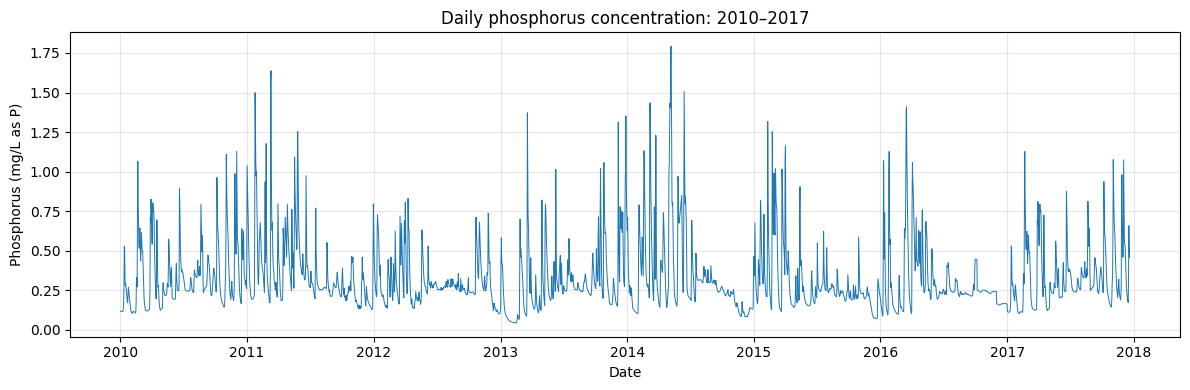

In [7]:
import matplotlib.pyplot as plt

# Select the phosphorus concentration column
phosphorus_column = df.columns[1]

# Plot phosphorus against date
plt.figure(figsize=(12, 4))
plt.plot(
    df["Date"],
    df[phosphorus_column],
    linewidth=0.7
)

plt.title("Daily phosphorus concentration: 2010–2017")
plt.xlabel("Date")
plt.ylabel("Phosphorus (mg/L as P)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


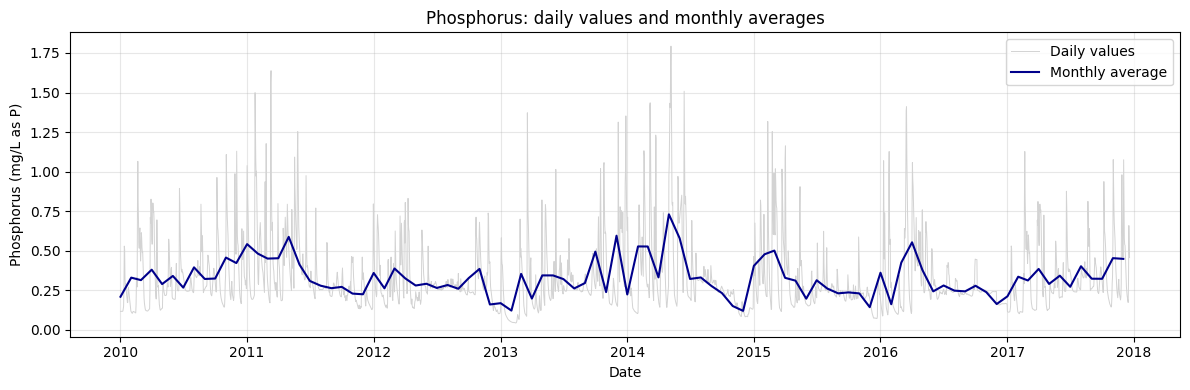

In [8]:
# Put dates on the index so we can group by month
phosphorus_daily = df.set_index("Date")[phosphorus_column]

# Calculate the average for each calendar month
phosphorus_monthly = phosphorus_daily.resample("MS").mean()

# Compare daily values with monthly averages
plt.figure(figsize=(12, 4))

plt.plot(
    phosphorus_daily,
    color="lightgray",
    linewidth=0.7,
    label="Daily values"
)

plt.plot(
    phosphorus_monthly,
    color="darkblue",
    linewidth=1.5,
    label="Monthly average"
)

plt.title("Phosphorus: daily values and monthly averages")
plt.xlabel("Date")
plt.ylabel("Phosphorus (mg/L as P)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


,Average phosphorus (mg/L as P),Complete months included
Jan,0.310,8
Feb,0.337,8
Mar,0.409,8
Apr,0.369,8
May,0.401,8
Jun,0.344,8
Jul,0.294,8
Aug,0.308,8
Sep,0.277,8
Oct,0.311,8


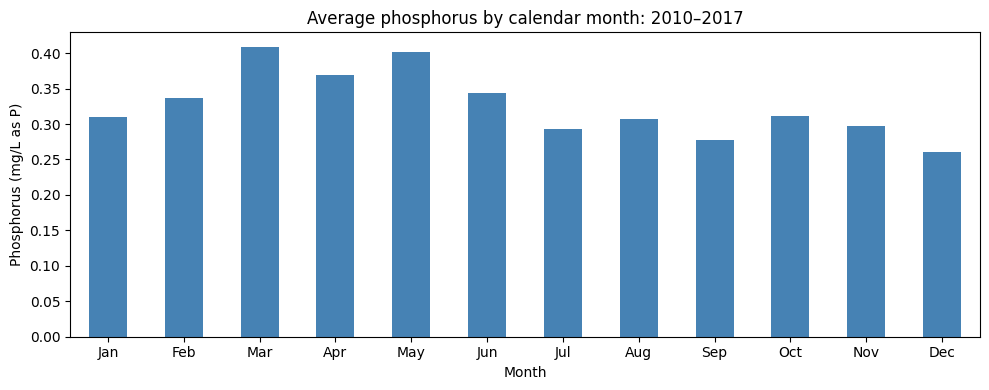

In [9]:
# Count available daily values in each month
monthly_counts = phosphorus_daily.resample("MS").count()

# Keep only months with a value for every calendar day
complete_months = phosphorus_monthly[
    monthly_counts == phosphorus_monthly.index.days_in_month
]

# Average January values together, February values together, etc.
seasonal_average = complete_months.groupby(
    complete_months.index.month
).mean()

# Show how many years contribute to each calendar month
months = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

seasonal_summary = pd.DataFrame({
    "Average phosphorus (mg/L as P)": seasonal_average,
    "Complete months included": complete_months.groupby(
        complete_months.index.month
    ).count()
})

seasonal_summary.index = months
display(seasonal_summary.round(3))

seasonal_summary.iloc[:, 0].plot(
    kind="bar", figsize=(10, 4), color="steelblue"
)

plt.title("Average phosphorus by calendar month: 2010–2017")
plt.xlabel("Month")
plt.ylabel("Phosphorus (mg/L as P)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [10]:
# Create a table with one row for each year
monthly_table = complete_months.to_frame(name="Phosphorus")
monthly_table["Year"] = monthly_table.index.year
monthly_table["Month"] = monthly_table.index.month

# Arrange years as rows and calendar months as columns
year_month_table = monthly_table.pivot(
    index="Year",
    columns="Month",
    values="Phosphorus"
)

year_month_table = year_month_table.reindex(columns=range(1, 13))
year_month_table.columns = months

display(year_month_table.round(3))

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
Year,,,,,,,,,,,,
2010,0.209,0.330,0.314,0.380,0.289,0.341,0.267,0.395,0.322,0.324,0.457,0.422
2011,0.542,0.482,0.450,0.453,0.588,0.413,0.309,0.279,0.263,0.272,0.229,0.225
2012,0.360,0.262,0.388,0.325,0.280,0.291,0.265,0.283,0.260,0.327,0.385,0.160
2013,0.169,0.122,0.354,0.198,0.344,0.344,0.321,0.262,0.296,0.494,0.239,0.595
2014,0.224,0.527,0.527,0.332,0.730,0.579,0.322,0.331,0.277,0.232,0.151,0.120
2015,0.404,0.478,0.501,0.329,0.311,0.197,0.313,0.261,0.231,0.237,0.230,0.143
2016,0.361,0.162,0.425,0.553,0.378,0.243,0.280,0.248,0.243,0.279,0.238,0.163
2017,0.212,0.336,0.312,0.385,0.290,0.342,0.272,0.402,0.323,0.323,0.453,NaN


In [11]:
# Compare the monthly values for 2010 and 2017
comparison = year_month_table.loc[[2010, 2017]].T

# Calculate the absolute difference for each month
comparison["Absolute difference"] = (
    comparison[2017] - comparison[2010]
).abs()

display(comparison.round(4))

Year,2010,2017,Absolute difference
Jan,0.2092,0.2118,0.0025
Feb,0.3300,0.3358,0.0059
Mar,0.3143,0.3121,0.0022
Apr,0.3802,0.3851,0.0049
May,0.2892,0.2901,0.0009
Jun,0.3407,0.3424,0.0017
Jul,0.2669,0.2722,0.0053
Aug,0.3949,0.4019,0.0069
Sep,0.3216,0.3232,0.0016
Oct,0.3244,0.3227,0.0016


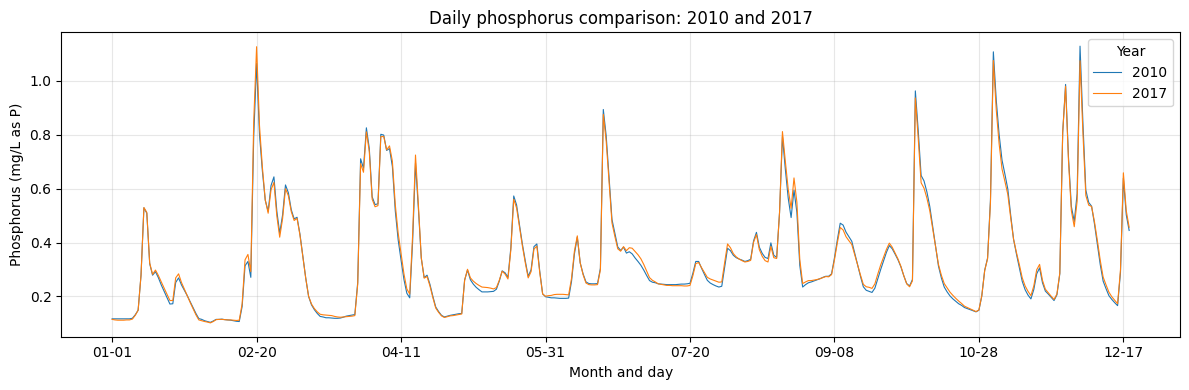

Matched calendar days: 353


In [12]:
# Extract daily phosphorus values for each year
daily_comparison = df[
    ["Date", phosphorus_column]
].copy()

daily_comparison["Year"] = daily_comparison["Date"].dt.year
daily_comparison["Month_day"] = (
    daily_comparison["Date"].dt.strftime("%m-%d")
)

# Match the same calendar dates across the two years
daily_comparison = daily_comparison[
    daily_comparison["Year"].isin([2010, 2017])
].pivot(
    index="Month_day",
    columns="Year",
    values=phosphorus_column
)

# Keep only dates available in both years
matched_days = daily_comparison.dropna()

matched_days.plot(figsize=(12, 4), linewidth=0.8)
plt.title("Daily phosphorus comparison: 2010 and 2017")
plt.xlabel("Month and day")
plt.ylabel("Phosphorus (mg/L as P)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Matched calendar days:", len(matched_days))

In [ ]:
## Data-quality finding:
## Phosphorus values for 2010 and 2017 show closely overlapping
## daily patterns across 353 matched calendar dates.

## Status:
## The cause is unverified. Original values remain unchanged.
## Source verification is required before interpreting model
#  performance or future projections as research findings.

In [13]:
# Read the first sheet without treating any row as a header
source_preview = pd.read_excel(
    workbook,
    sheet_name="Phosphorus-1",
    header=None,
    nrows=30
)

# Display its introductory information
display(source_preview)

,0,1,2,3
0,NaN,NaN,# Additional info: https://waterdata.usgs.gov/...,NaN
1,NaN,NaN,# Additional info: https://waterdata.usgs.gov/...,NaN
2,NaN,NaN,#,NaN
3,NaN,NaN,# Contact: gs-w_waterdata_support@usgs.gov,NaN
4,NaN,NaN,# retrieved: 2025-03-19 08:59:25 EDT (ca...,NaN
5,NaN,NaN,#,NaN
6,NaN,NaN,# Data for the following 1 site(s) are contain...,NaN
7,NaN,NaN,# USGS 04182000 ST. MARYS RIVER NEAR FORT W...,NaN
8,NaN,NaN,# --------------------------------------------...,NaN
9,NaN,NaN,#,NaN
